# Opening the Transformer: Attention, Encoder, Decoder and Inference


In [44]:
import os
import time
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import transformers
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM
from transformers import T5ForConditionalGeneration, T5Tokenizer
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings('ignore')

# seeds, as the practical asks
torch.manual_seed(42)
np.random.seed(42)

os.makedirs('plots', exist_ok=True)
sns.set_theme(style='whitegrid')

SENT_ID = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
MLM_ID = 'distilbert/distilbert-base-uncased'
GPT_ID = 'openai-community/gpt2'
T5_ID = 'google-t5/t5-small'



# Task 1: Introduction, History, Pipelines & Tokenizer


## 1.1 Install and first pipeline
Install once in the terminal: `pip install transformers torch datasets matplotlib seaborn numpy pandas`.
One `pipeline(...)` call hides three steps: **tokenisation** (text to ids), the **model forward pass** (ids to logits) and **post-processing** (softmax and label lookup).

In [2]:
clf = pipeline('sentiment-analysis', model=SENT_ID)

my_sentences = [
    'I loved this film, the acting was brilliant.',                 # positive
    'This was a complete waste of two hours.',                      # negative
    'The plot was dull and the ending made no sense.',              # negative
    'What a wonderful surprise, I would watch it again!',           # positive
    'I cannot say that I did not enjoy it.',                        # tricky: double negation
]

results = clf(my_sentences)
table_11 = pd.DataFrame({'sentence': my_sentences,
                         'label': [r['label'] for r in results],
                         'score': [round(r['score'], 4) for r in results]})
table_11

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2166.25it/s]


,sentence,label,score
0,"I loved this film, the acting was brilliant.",POSITIVE,0.9999
1,This was a complete waste of two hours.,NEGATIVE,0.9998
2,The plot was dull and the ending made no sense.,NEGATIVE,0.9998
3,"What a wonderful surprise, I would watch it ag...",POSITIVE,0.9999
4,I cannot say that I did not enjoy it.,NEGATIVE,0.9992


## 1.4 Tokenizer in action

In [3]:
tok = AutoTokenizer.from_pretrained(SENT_ID)

text = 'Transformers are surprisingly easy to understand.'
tokens = tok.tokenize(text)
enc = tok(text)

print('tokens        :', tokens)
print('input_ids     :', enc['input_ids'])
print('attention_mask:', enc['attention_mask'])
print('with specials :', tok.convert_ids_to_tokens(enc['input_ids']))

# a rare / long word gets split into sub-word pieces
rare = 'Antidisestablishmentarianism is a ridiculously long word.'
print()
print('rare word     :', tok.tokenize(rare))

tokens        : ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids     : [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
with specials : ['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']

rare word     : ['anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism', 'is', 'a', 'ridiculous', '##ly', 'long', 'word', '.']



## 1.5 Batching and padding

In [4]:
batch = tok(['Great movie.', 'The story was slow at first but the ending was truly worth the wait.'],
            padding=True, return_tensors='pt')

for i in range(2):
    print('sentence', i)
    print('  input_ids     :', batch['input_ids'][i].tolist())
    print('  attention_mask:', batch['attention_mask'][i].tolist())
print('pad token id:', tok.pad_token_id)

sentence 0
  input_ids     : [101, 2307, 3185, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  attention_mask: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
sentence 1
  input_ids     : [101, 1996, 2466, 2001, 4030, 2012, 2034, 2021, 1996, 4566, 2001, 5621, 4276, 1996, 3524, 1012, 102]
  attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
pad token id: 0



## 1.6 Model anatomy at a glance

In [5]:
# eager attention is needed so that attention weights can be returned
sent_model = AutoModelForSequenceClassification.from_pretrained(SENT_ID, attn_implementation='eager')
sent_model.eval()

cfg = sent_model.config
total_params = sum(p.numel() for p in sent_model.parameters())

print('layers          :', cfg.n_layers)
print('attention heads :', cfg.n_heads)
print('hidden size     :', cfg.dim)
print('FFN hidden size :', cfg.hidden_dim)
print('vocabulary size :', cfg.vocab_size)
print('max positions   :', cfg.max_position_embeddings)
print('total parameters:', f'{total_params:,}')
print()
print('first 15 parameter names:')
for name, p in list(sent_model.named_parameters())[:15]:
    print(f'  {name:70s} {tuple(p.shape)}')

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1336.88it/s]

layers          : 6
attention heads : 12
hidden size     : 768
FFN hidden size : 3072
vocabulary size : 30522
max positions   : 512
total parameters: 66,955,010

first 15 parameter names:
  distilbert.embeddings.word_embeddings.weight                           (30522, 768)
  distilbert.embeddings.position_embeddings.weight                       (512, 768)
  distilbert.embeddings.LayerNorm.weight                                 (768,)
  distilbert.embeddings.LayerNorm.bias                                   (768,)
  distilbert.transformer.layer.0.attention.q_lin.weight                  (768, 768)
  distilbert.transformer.layer.0.attention.q_lin.bias                    (768,)
  distilbert.transformer.layer.0.attention.k_lin.weight                  (768, 768)
  distilbert.transformer.layer.0.attention.k_lin.bias                    (768,)
  distilbert.transformer.layer.0.attention.v_lin.weight                  (768, 768)
  distilbert.transformer.layer.0.attention.v_lin.bias                 

In [6]:
anatomy = pd.DataFrame({
    'item': ['layers', 'attention heads', 'hidden size (d_model)', 'size per head', 'FFN hidden size',
             'vocabulary size', 'max position embeddings', 'total parameters'],
    'value': [cfg.n_layers, cfg.n_heads, cfg.dim, cfg.dim // cfg.n_heads, cfg.hidden_dim,
              cfg.vocab_size, cfg.max_position_embeddings, f'{total_params:,}']})
anatomy

,item,value
0,layers,6
1,attention heads,12
2,hidden size (d_model),768
3,size per head,64
4,FFN hidden size,3072
5,vocabulary size,30522
6,max position embeddings,512
7,total parameters,"66,955,010"


# Task 2: Self-Attention & Scaled Dot-Product Attention

## 2.2 Scaled dot-product attention from scratch

X        shape (4, 8)
Q        shape (4, 8)
K        shape (4, 8)
V        shape (4, 8)
scores   shape (4, 4)
weights  shape (4, 4)
output   shape (4, 8)

row sums of the attention weights: [1. 1. 1. 1.]
every row sums to 1: True


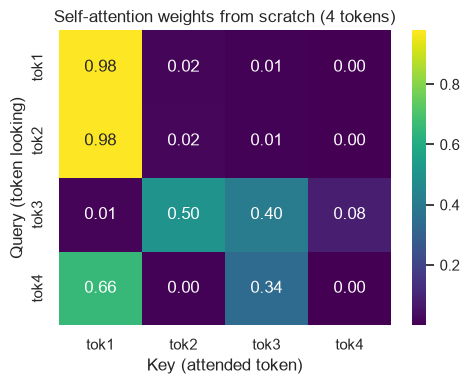

In [7]:
def softmax(x, axis=-1):
    # stable softmax: subtract the max first so exp() cannot overflow
    x = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(x)
    return e / np.sum(e, axis=axis, keepdims=True)


def attention_weights(Q, K, mask=None):
    # scaled dot-product scores -> (optional additive mask) -> softmax
    d_k = Q.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask
    return scores, softmax(scores, axis=-1)


def self_attention(X, Wq, Wk, Wv, mask=None):
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    scores, weights = attention_weights(Q, K, mask)
    out = weights @ V
    return Q, K, V, scores, weights, out


rng = np.random.default_rng(42)
n_tokens, d_model = 4, 8
X = rng.normal(size=(n_tokens, d_model))
Wq = rng.normal(size=(d_model, d_model))
Wk = rng.normal(size=(d_model, d_model))
Wv = rng.normal(size=(d_model, d_model))

Q, K, V, scores, weights, out = self_attention(X, Wq, Wk, Wv)

for name, arr in [('X', X), ('Q', Q), ('K', K), ('V', V), ('scores', scores), ('weights', weights), ('output', out)]:
    print(f'{name:8s} shape {arr.shape}')

print()
print('row sums of the attention weights:', weights.sum(axis=1))
print('every row sums to 1:', np.allclose(weights.sum(axis=1), 1.0))

tok_labels = ['tok1', 'tok2', 'tok3', 'tok4']
plt.figure(figsize=(5, 4))
sns.heatmap(weights, annot=True, fmt='.2f', cmap='viridis', xticklabels=tok_labels, yticklabels=tok_labels)
plt.title('Self-attention weights from scratch (4 tokens)')
plt.xlabel('Key (attended token)')
plt.ylabel('Query (token looking)')
plt.tight_layout()
plt.savefig('plots/attention_scratch.png', dpi=150)
plt.show()

## 2.3 Why divide by sqrt(d_k)?

In [8]:
def entropy(p):
    return -np.sum(p * np.log(p + 1e-12), axis=-1)

rows = []
for d_k in [4, 256]:
    max_probs = {'with scaling': [], 'without scaling': []}
    ents = {'with scaling': [], 'without scaling': []}
    score_std = {'with scaling': [], 'without scaling': []}
    rng = np.random.default_rng(0)
    for trial in range(200):
        Qr = rng.normal(size=(10, d_k))
        Kr = rng.normal(size=(10, d_k))
        raw = Qr @ Kr.T
        for label, s in [('with scaling', raw / np.sqrt(d_k)), ('without scaling', raw)]:
            p = softmax(s, axis=-1)
            max_probs[label].append(p.max(axis=1).mean())
            ents[label].append(entropy(p).mean())
            score_std[label].append(s.std())
    for label in ['without scaling', 'with scaling']:
        rows.append({'d_k': d_k, 'setting': label,
                     'score std': round(np.mean(score_std[label]), 2),
                     'mean max softmax prob': round(np.mean(max_probs[label]), 3),
                     'mean entropy': round(np.mean(ents[label]), 3)})

scaling_table = pd.DataFrame(rows)
print('uniform attention over 10 tokens would have entropy', round(np.log(10), 3))
scaling_table

uniform attention over 10 tokens would have entropy 2.303


,d_k,setting,score std,mean max softmax prob,mean entropy
0,4,without scaling,1.95,0.490,1.445
1,4,with scaling,0.97,0.302,1.954
2,256,without scaling,15.84,0.934,0.164
3,256,with scaling,0.99,0.320,1.924



## 2.4 Self-attention vs Luong attention

In [9]:
def luong_dot_attention(encoder_states, decoder_state):
    scores = encoder_states @ decoder_state          # one score per encoder state
    weights = softmax(scores)
    context = weights @ encoder_states               # weighted sum of encoder states
    return scores, weights, context


rng = np.random.default_rng(1)
encoder_states = rng.normal(size=(5, 8))
decoder_state = rng.normal(size=(8,))

l_scores, l_weights, l_context = luong_dot_attention(encoder_states, decoder_state)
print('scores  :', np.round(l_scores, 3))
print('weights :', np.round(l_weights, 3), '| sum =', l_weights.sum().round(3))
print('context :', np.round(l_context, 3), '| shape', l_context.shape)

scores  : [-0.138 -1.431 -0.04   5.668 -1.761]
weights : [0.003 0.001 0.003 0.992 0.001] | sum = 1.0
context : [-2.689 -1.872 -0.175 -0.423  0.214  0.215  2.104 -1.098] | shape (8,)




## 2.5 Attention is order-blind (demonstration)

In [10]:
rng = np.random.default_rng(42)
X = rng.normal(size=(4, 8))
Wq, Wk, Wv = [rng.normal(size=(8, 8)) for _ in range(3)]

perm = np.array([2, 0, 3, 1])                  # fixed permutation of the 4 rows
_, _, _, _, _, out_original = self_attention(X, Wq, Wk, Wv)
_, _, _, _, _, out_shuffled = self_attention(X[perm], Wq, Wk, Wv)

print('output rows of shuffled input are the same rows, just shuffled:',
      np.allclose(out_shuffled, out_original[perm]))
print('max difference after re-permuting:', np.abs(out_shuffled - out_original[perm]).max())

output rows of shuffled input are the same rows, just shuffled: True
max difference after re-permuting: 4.440892098500626e-16



## 2.6 Verify against a real model

In [11]:
sentence = 'The movie was surprisingly good and the acting was great.'
inputs = tok(sentence, return_tensors='pt')

with torch.no_grad():
    out_real = sent_model(**inputs, output_hidden_states=True, output_attentions=True)

print(sent_model.distilbert.transformer.layer[0])

TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (activation): GELUActivation()
  )
  (output_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
)


In [12]:
layer0_attn = sent_model.distilbert.transformer.layer[0].attention
n_heads = sent_model.config.n_heads
d_head = sent_model.config.dim // n_heads          # 768 / 12 = 64

with torch.no_grad():
    h0 = out_real.hidden_states[0]                 # input of layer 0 (embeddings output)
    q = layer0_attn.q_lin(h0)
    k = layer0_attn.k_lin(h0)

B, T, D = q.shape
q = q.view(B, T, n_heads, d_head).transpose(1, 2)  # (batch, heads, tokens, 64)
k = k.view(B, T, n_heads, d_head).transpose(1, 2)

my_scores = (q @ k.transpose(-1, -2)) / math.sqrt(d_head)
# one sentence in the batch, so there is no padding mask to add
my_weights = torch.softmax(my_scores, dim=-1)

mine = my_weights[0, 0].numpy()                    # head 0
real = out_real.attentions[0][0, 0].numpy()        # layer 0, batch 0, head 0

print('shape mine / real   :', mine.shape, real.shape)
print('max absolute diff   :', np.abs(mine - real).max())
print('np.allclose(1e-4)   :', np.allclose(mine, real, atol=1e-4))

shape mine / real   : (13, 13) (13, 13)
max absolute diff   : 0.0
np.allclose(1e-4)   : True


# Task 3: Multi-Head Attention, Positional Encoding & Layer Normalisation


## 3.2 Extract and plot real attention heads

type: <class 'tuple'> | number of layers: 6
layer 0: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)
layer 1: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)
layer 2: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)
layer 3: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)
layer 4: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)
layer 5: shape (1, 12, 15, 15)   (batch, heads, tokens, tokens)


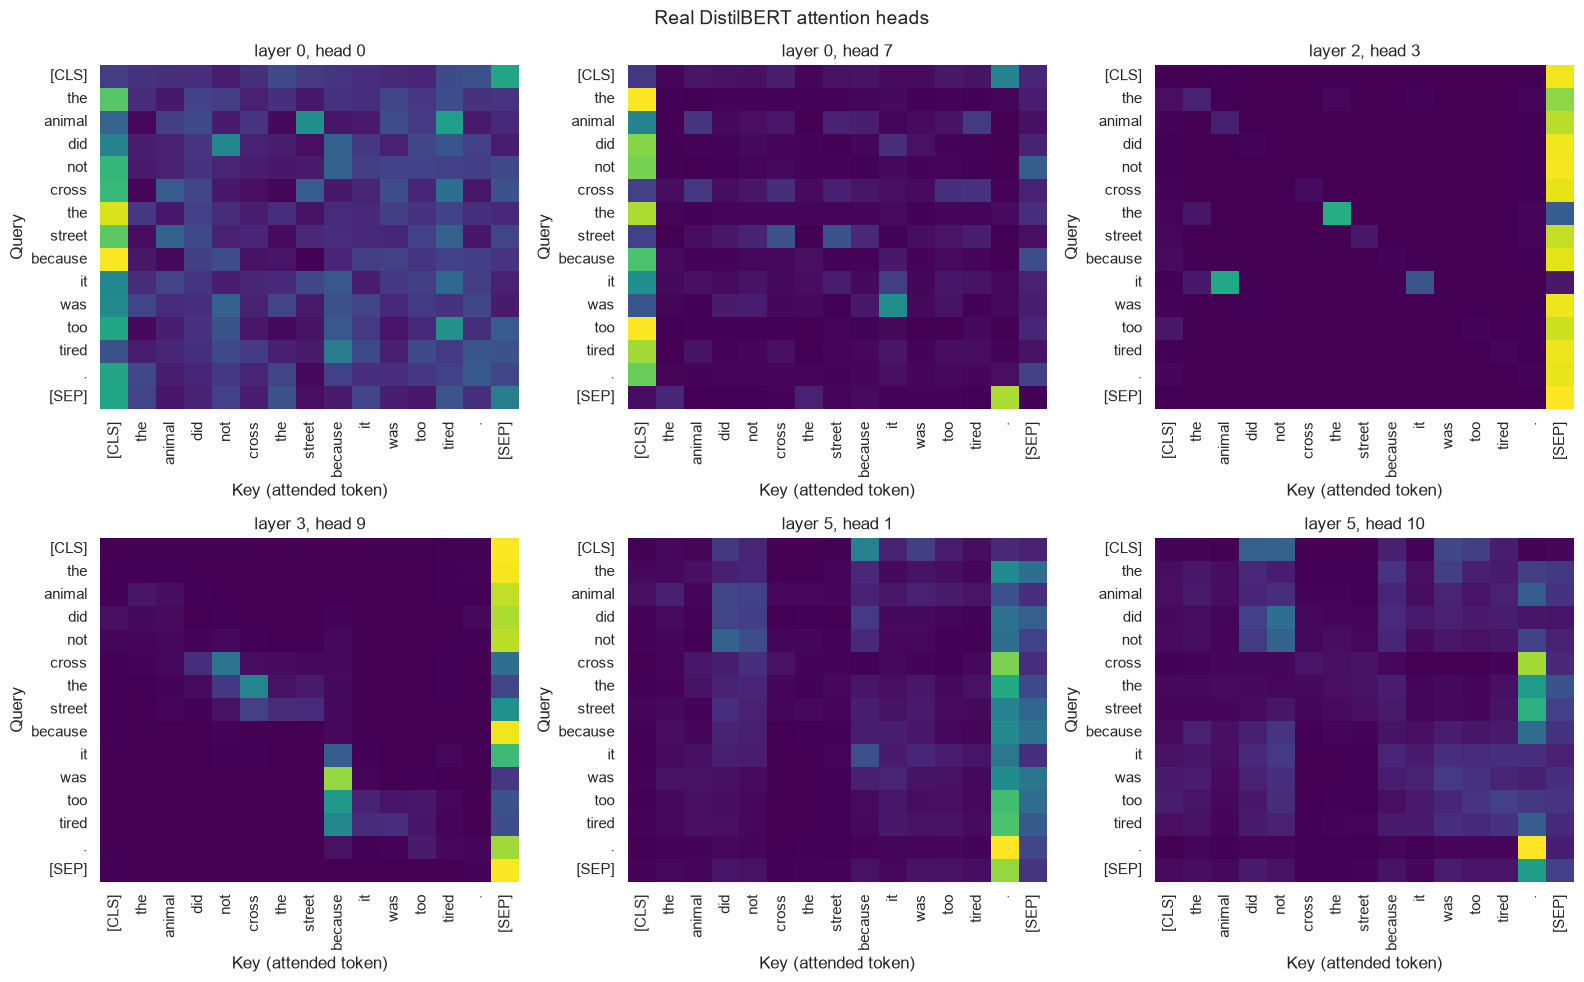

In [13]:
sentence = 'The animal did not cross the street because it was too tired.'
inputs = tok(sentence, return_tensors='pt')
tokens = tok.convert_ids_to_tokens(inputs['input_ids'][0])

with torch.no_grad():
    out_heads = sent_model(**inputs, output_attentions=True)

attn = out_heads.attentions
print('type:', type(attn), '| number of layers:', len(attn))
for i, a in enumerate(attn):
    print(f'layer {i}: shape {tuple(a.shape)}   (batch, heads, tokens, tokens)')

# six heads: a mix of early, middle and late layers
chosen = [(0, 0), (0, 7), (2, 3), (3, 9), (5, 1), (5, 10)]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (layer, head) in zip(axes.ravel(), chosen):
    sns.heatmap(attn[layer][0, head].numpy(), ax=ax, cmap='viridis', cbar=False,
                xticklabels=tokens, yticklabels=tokens)
    ax.set_title(f'layer {layer}, head {head}')
    ax.set_xlabel('Key (attended token)')
    ax.set_ylabel('Query')
    ax.tick_params(axis='x', rotation=90)
plt.suptitle('Real DistilBERT attention heads', fontsize=14)
plt.tight_layout()
plt.savefig('plots/attention_heads.png', dpi=150)
plt.show()

In [14]:
# numbers to support what I describe: where does each plotted head look?
it_idx = tokens.index('it')
rows = []
for layer, head in chosen:
    a = attn[layer][0, head].numpy()
    rows.append({'head': f'L{layer}-H{head}',
                 'avg attention to [CLS]': round(a[:, 0].mean(), 3),
                 'avg attention to [SEP]': round(a[:, -1].mean(), 3),
                 'avg attention to previous token': round(np.mean([a[i, i - 1] for i in range(1, len(tokens))]), 3),
                 "'it' attends most to": tokens[a[it_idx].argmax()]})
pd.DataFrame(rows)

,head,avg attention to [CLS],avg attention to [SEP],avg attention to previous token,'it' attends most to
0,L0-H0,0.195,0.076,0.059,[CLS]
1,L0-H7,0.464,0.089,0.148,[CLS]
2,L2-H3,0.016,0.845,0.003,animal
3,L3-H9,0.007,0.643,0.105,[SEP]
4,L5-H1,0.009,0.177,0.099,.
5,L5-H10,0.027,0.105,0.079,not




## 3.3 Head diversity measurement

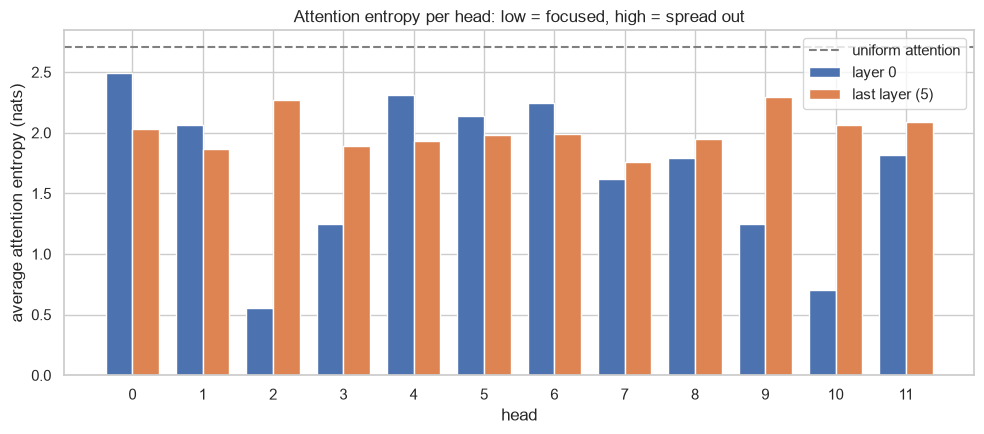

layer 0   mean / min / max entropy: 1.686 0.553 2.494
last layer mean / min / max entropy: 2.01 1.762 2.291


In [15]:
def head_entropies(a):
    # a: (heads, tokens, tokens) -> mean entropy of attention rows per head
    p = a.numpy()
    ent = -np.sum(p * np.log(p + 1e-12), axis=-1)     # (heads, tokens)
    return ent.mean(axis=1)

ent_first = head_entropies(attn[0][0])
ent_last = head_entropies(attn[-1][0])

x = np.arange(12)
width = 0.38
plt.figure(figsize=(10, 4.5))
plt.bar(x - width / 2, ent_first, width, label='layer 0')
plt.bar(x + width / 2, ent_last, width, label='last layer (5)')
plt.axhline(np.log(len(tokens)), color='grey', linestyle='--', label='uniform attention')
plt.xticks(x)
plt.xlabel('head')
plt.ylabel('average attention entropy (nats)')
plt.title('Attention entropy per head: low = focused, high = spread out')
plt.legend()
plt.tight_layout()
plt.savefig('plots/head_entropy.png', dpi=150)
plt.show()

print('layer 0   mean / min / max entropy:', ent_first.mean().round(3), ent_first.min().round(3), ent_first.max().round(3))
print('last layer mean / min / max entropy:', ent_last.mean().round(3), ent_last.min().round(3), ent_last.max().round(3))



## 3.4 Sinusoidal positional encoding from scratch

PE shape: (50, 128) | value range: -1.0 to 1.0


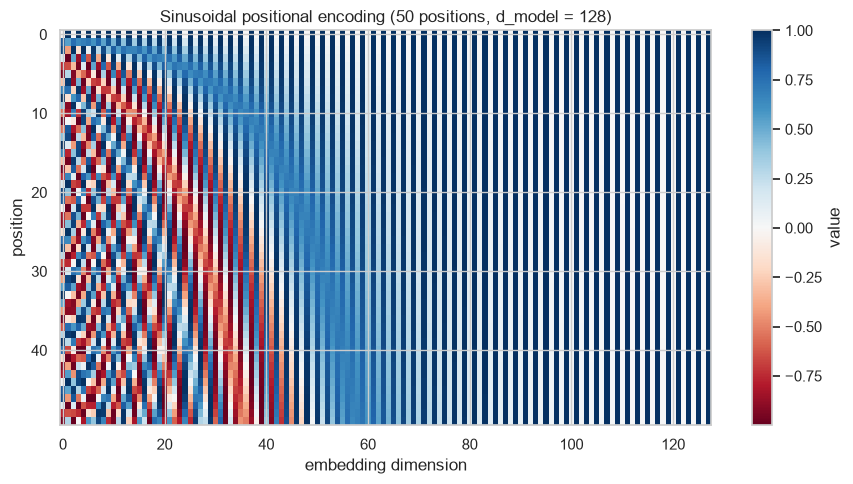

In [16]:
def positional_encoding(n_positions, d_model):
    pe = np.zeros((n_positions, d_model))
    pos = np.arange(n_positions)[:, None]
    i = np.arange(0, d_model, 2)[None, :]
    angle = pos / np.power(10000, i / d_model)
    pe[:, 0::2] = np.sin(angle)       # PE(pos, 2i)
    pe[:, 1::2] = np.cos(angle)       # PE(pos, 2i+1)
    return pe

PE = positional_encoding(50, 128)
print('PE shape:', PE.shape, '| value range:', PE.min().round(2), 'to', PE.max().round(2))

plt.figure(figsize=(9, 5))
plt.imshow(PE, aspect='auto', cmap='RdBu')
plt.colorbar(label='value')
plt.xlabel('embedding dimension')
plt.ylabel('position')
plt.title('Sinusoidal positional encoding (50 positions, d_model = 128)')
plt.tight_layout()
plt.savefig('plots/positional_encoding.png', dpi=150)
plt.show()


## 3.5 Position makes identical words different

In [17]:
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

rng = np.random.default_rng(42)
word = rng.normal(size=128)
PE = positional_encoding(50, 128)

at_3 = word + PE[3]
at_20 = word + PE[20]

print('cosine similarity WITHOUT position encoding:', cosine(word, word))
print('cosine similarity WITH position encoding   :', round(cosine(at_3, at_20), 4))

cosine similarity WITHOUT position encoding: 1.0
cosine similarity WITH position encoding   : 0.8261



## 3.6 Learned positional embeddings in a real model

position embedding shape: (512, 768)


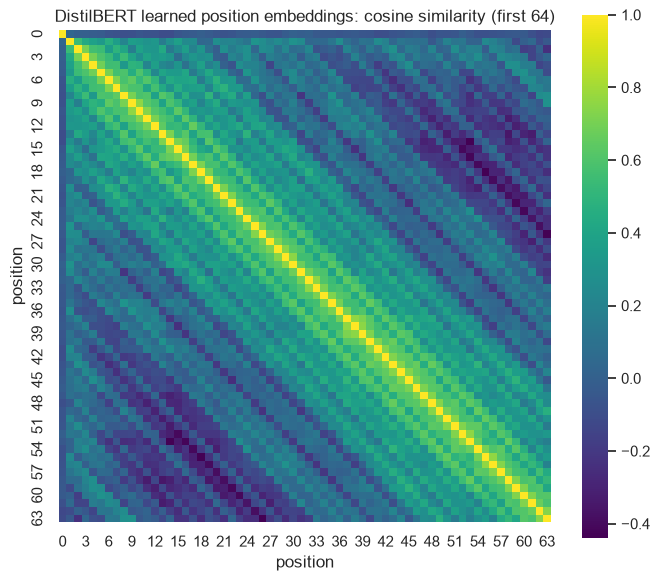

In [18]:
pos_w = sent_model.distilbert.embeddings.position_embeddings.weight.detach().numpy()
print('position embedding shape:', pos_w.shape)

first = pos_w[:64]
norm = first / np.linalg.norm(first, axis=1, keepdims=True)
cos_matrix = norm @ norm.T

plt.figure(figsize=(7, 6))
sns.heatmap(cos_matrix, cmap='viridis', square=True)
plt.xlabel('position')
plt.ylabel('position')
plt.title('DistilBERT learned position embeddings: cosine similarity (first 64)')
plt.tight_layout()
plt.savefig('plots/learned_positions.png', dpi=150)
plt.show()



## 3.7 Layer normalisation from scratch

In [19]:
def layer_norm(x, gamma=1.0, beta=0.0, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)           # over the FEATURE dimension of each token
    var = x.var(axis=-1, keepdims=True)
    return gamma * (x - mean) / np.sqrt(var + eps) + beta


rng = np.random.default_rng(42)
M = rng.normal(loc=3.0, scale=2.0, size=(4, 8))     # 4 tokens x 8 features
ln_out = layer_norm(M)

print('per-token mean after LayerNorm:', ln_out.mean(axis=1).round(6))
print('per-token std  after LayerNorm:', ln_out.std(axis=1).round(4))

torch_ln = torch.nn.LayerNorm(8)                    # gamma = 1, beta = 0 at start
ref = torch_ln(torch.tensor(M, dtype=torch.float32)).detach().numpy()
print('matches torch.nn.LayerNorm:', np.allclose(ln_out, ref, atol=1e-5))

per-token mean after LayerNorm: [-0. -0.  0.  0.]
per-token std  after LayerNorm: [1. 1. 1. 1.]
matches torch.nn.LayerNorm: True


## 3.8 LayerNorm vs BatchNorm

In [20]:
# BatchNorm normalises each FEATURE (column) across the 4 tokens
bn_out = (M - M.mean(axis=0, keepdims=True)) / np.sqrt(M.var(axis=0, keepdims=True) + 1e-5)

print('BatchNorm: per-FEATURE mean:', bn_out.mean(axis=0).round(4))
print('BatchNorm: per-TOKEN   mean:', bn_out.mean(axis=1).round(4), '<- not normalised')
print('BatchNorm: per-TOKEN   std :', bn_out.std(axis=1).round(4), '<- not normalised')
print()
print('LayerNorm: per-TOKEN   mean:', ln_out.mean(axis=1).round(4))
print('LayerNorm: per-TOKEN   std :', ln_out.std(axis=1).round(4))

ln = sent_model.distilbert.embeddings.LayerNorm
print()
print('DistilBERT embeddings LayerNorm weight (gamma) shape:', tuple(ln.weight.shape))
print('bias (beta) shape                                   :', tuple(ln.bias.shape))
print('gamma mean/std:', ln.weight.mean().item(), ln.weight.std().item())
print('beta  mean/std:', ln.bias.mean().item(), ln.bias.std().item())

BatchNorm: per-FEATURE mean: [-0.  0.  0.  0. -0.  0. -0. -0.]
BatchNorm: per-TOKEN   mean: [-0.3335  0.0807  0.099   0.1538] <- not normalised
BatchNorm: per-TOKEN   std : [0.9793 0.8888 0.8452 1.177 ] <- not normalised

LayerNorm: per-TOKEN   mean: [-0. -0.  0.  0.]
LayerNorm: per-TOKEN   std : [1. 1. 1. 1.]

DistilBERT embeddings LayerNorm weight (gamma) shape: (768,)
bias (beta) shape                                   : (768,)
gamma mean/std: 0.7443591952323914 0.13582652807235718
beta  mean/std: -0.009963031858205795 0.09107962995767593


# Task 4: Transformer Encoder Architecture & Masked Self-Attention


## 4.2 Print and read the real encoder

In [21]:
print(sent_model.distilbert)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [22]:
block = sent_model.distilbert.transformer.layer[0]
module_rows = []
for name, m in block.named_modules():
    if name == '':
        continue
    shape = ''
    if hasattr(m, 'weight') and m.weight is not None:
        shape = str(tuple(m.weight.shape))
    module_rows.append({'module name (inside one block)': name, 'type': type(m).__name__, 'weight shape': shape})
pd.DataFrame(module_rows)

,module name (inside one block),type,weight shape
0,attention,DistilBertSelfAttention,
1,attention.q_lin,Linear,"(768, 768)"
2,attention.k_lin,Linear,"(768, 768)"
3,attention.v_lin,Linear,"(768, 768)"
4,attention.out_lin,Linear,"(768, 768)"
5,attention.dropout,Dropout,
6,sa_layer_norm,LayerNorm,"(768,)"
7,ffn,FFN,
8,ffn.dropout,Dropout,
9,ffn.lin1,Linear,"(3072, 768)"




## 4.3 Where do the parameters live?

          component  parameters  share %
         embeddings    23834112    35.60
          attention    14174208    21.17
       feed-forward    28334592    42.32
        layer norms       19968     0.03
classification head      592130     0.88


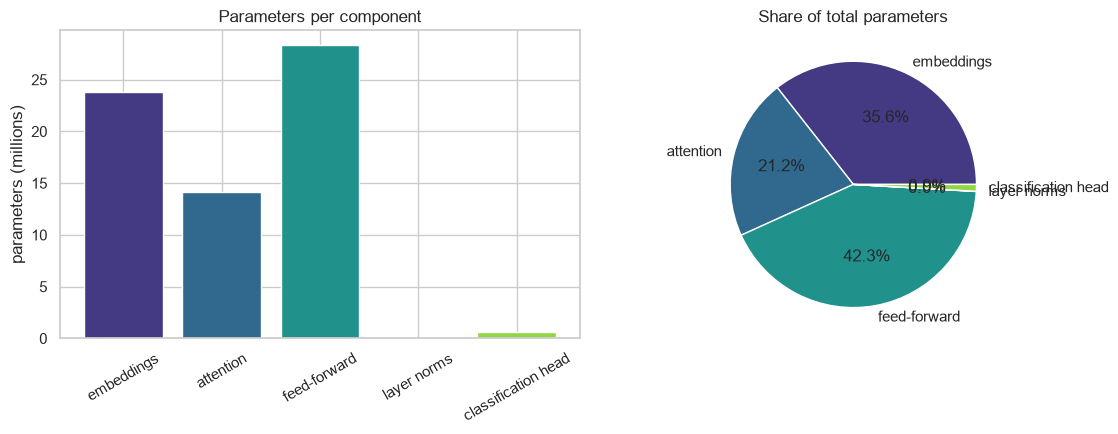

In [23]:
groups = {'embeddings': 0, 'attention': 0, 'feed-forward': 0, 'layer norms': 0, 'classification head': 0}

for name, p in sent_model.named_parameters():
    n = p.numel()
    if 'LayerNorm' in name or 'layer_norm' in name:
        groups['layer norms'] += n
    elif name.startswith('distilbert.embeddings'):
        groups['embeddings'] += n
    elif '.attention.' in name:
        groups['attention'] += n
    elif '.ffn.' in name:
        groups['feed-forward'] += n
    else:
        groups['classification head'] += n

total = sum(groups.values())
assert total == total_params, (total, total_params)

param_table = pd.DataFrame({'component': list(groups), 'parameters': list(groups.values())})
param_table['share %'] = (param_table['parameters'] / total * 100).round(2)
print(param_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(param_table['component'], param_table['parameters'] / 1e6, color=sns.color_palette('viridis', 5))
axes[0].set_ylabel('parameters (millions)')
axes[0].set_title('Parameters per component')
axes[0].tick_params(axis='x', rotation=30)
axes[1].pie(param_table['parameters'], labels=param_table['component'], autopct='%1.1f%%',
            colors=sns.color_palette('viridis', 5))
axes[1].set_title('Share of total parameters')
plt.tight_layout()
plt.savefig('plots/parameter_distribution.png', dpi=150)
plt.show()


## 4.4 Use the encoder: fill-mask

In [24]:
fill = pipeline('fill-mask', model=MLM_ID)
mask = fill.tokenizer.mask_token

mask_sentences = [
    f'The capital of France is {mask}.',
    f'I would like a cup of {mask} in the morning.',
    f'She opened the door and walked into the {mask}.',
]

for s in mask_sentences:
    print(s)
    for r in fill(s, top_k=3):
        print(f"    {r['token_str']:12s} score = {r['score']:.4f}")
    print()

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 1666.70it/s]


The capital of France is [MASK].
    marseille    score = 0.1427
    nantes       score = 0.0902
    toulouse     score = 0.0881

I would like a cup of [MASK] in the morning.
    coffee       score = 0.6222
    tea          score = 0.2893
    water        score = 0.0211

She opened the door and walked into the [MASK].
    hallway      score = 0.1309
    room         score = 0.1199
    kitchen      score = 0.1188





## 4.5 Bidirectional attention heatmap

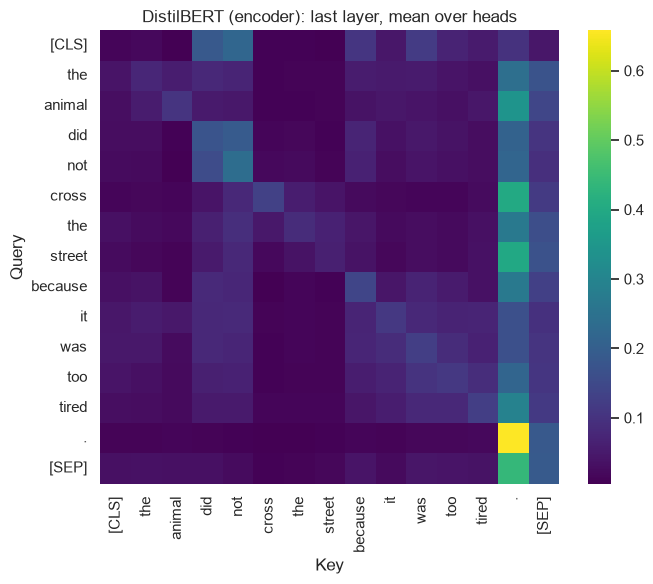

largest weight above the diagonal : 0.3991
largest weight below the diagonal : 0.4407
non-zero weights above diagonal   : True


In [25]:
sentence = 'The animal did not cross the street because it was too tired.'
inputs = tok(sentence, return_tensors='pt')
tokens = tok.convert_ids_to_tokens(inputs['input_ids'][0])
with torch.no_grad():
    o = sent_model(**inputs, output_attentions=True)

bi = o.attentions[-1][0].mean(dim=0).numpy()            # last layer, average over 12 heads

plt.figure(figsize=(7, 6))
sns.heatmap(bi, cmap='viridis', xticklabels=tokens, yticklabels=tokens)
plt.title('DistilBERT (encoder): last layer, mean over heads')
plt.xlabel('Key')
plt.ylabel('Query')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('plots/attention_bidirectional.png', dpi=150)
plt.show()

print('largest weight above the diagonal :', np.triu(bi, k=1).max().round(4))
print('largest weight below the diagonal :', np.tril(bi, k=-1).max().round(4))
print('non-zero weights above diagonal   :', bool(np.triu(bi, k=1).max() > 1e-3))



## 4.6 Masked (causal) self-attention from scratch

[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]

lower-triangular: True
rows sum to 1   : True


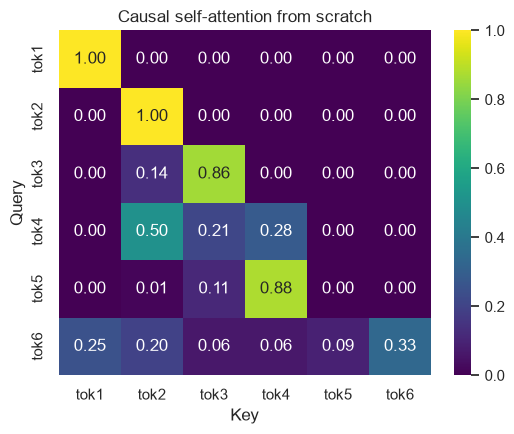

In [26]:
n = 6
rng = np.random.default_rng(42)
Xc = rng.normal(size=(n, 8))
Wq, Wk, Wv = [rng.normal(size=(8, 8)) for _ in range(3)]

# -inf above the diagonal, 0 on and below it
causal_mask = np.triu(np.full((n, n), -np.inf), k=1)
print(causal_mask)

_, _, _, scores_c, weights_c, out_c = self_attention(Xc, Wq, Wk, Wv, mask=causal_mask)

print()
print('lower-triangular:', np.allclose(weights_c, np.tril(weights_c)))
print('rows sum to 1   :', np.allclose(weights_c.sum(axis=1), 1.0))

labels = [f'tok{i + 1}' for i in range(n)]
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(weights_c, annot=True, fmt='.2f', cmap='viridis', xticklabels=labels, yticklabels=labels)
plt.title('Causal self-attention from scratch')
plt.xlabel('Key')
plt.ylabel('Query')
plt.tight_layout()
plt.savefig('plots/causal_mask.png', dpi=150)
plt.show()



## 4.7 Causal mask in a real decoder

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 308.27it/s]


largest entry above the diagonal: 0.0
np.triu(attn, k=1).max() < 1e-6 : True


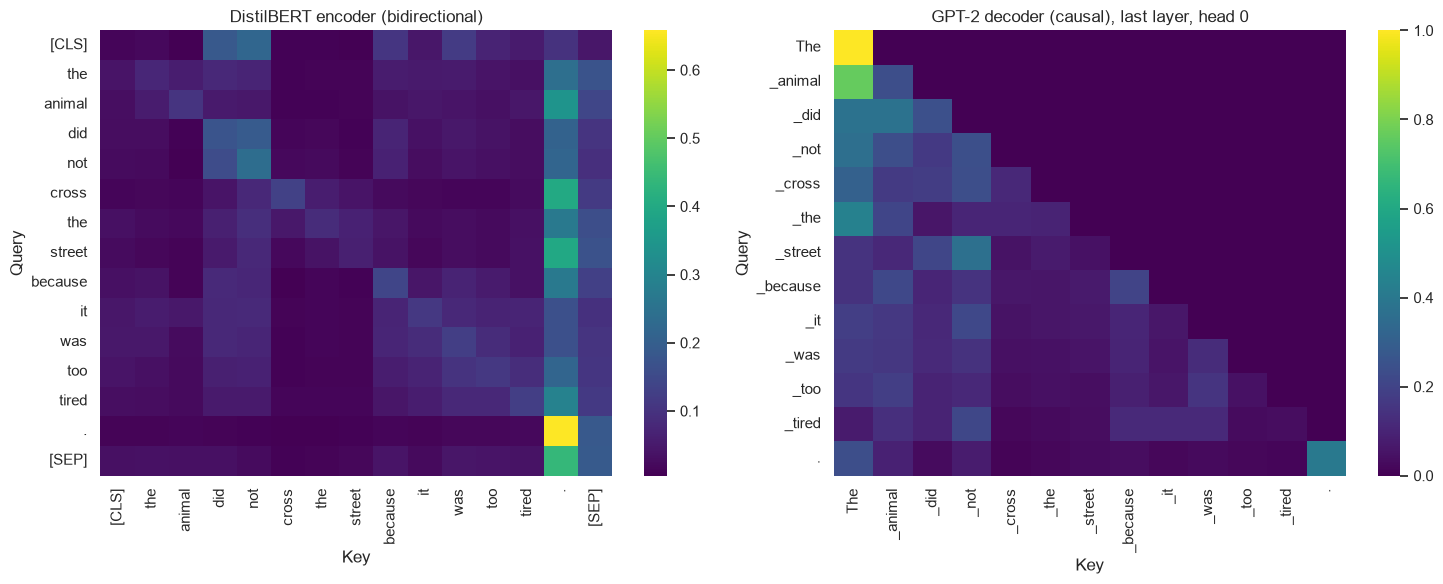

In [27]:
gpt_tok = AutoTokenizer.from_pretrained(GPT_ID)
gpt = AutoModelForCausalLM.from_pretrained(GPT_ID, attn_implementation='eager')
gpt.eval()

g_inputs = gpt_tok('The animal did not cross the street because it was too tired.', return_tensors='pt')
g_tokens = [t.replace('\u0120', '_') for t in gpt_tok.convert_ids_to_tokens(g_inputs['input_ids'][0])]

with torch.no_grad():
    g_out = gpt(**g_inputs, output_attentions=True)

g_attn = g_out.attentions[-1][0, 0].numpy()           # last layer, head 0
print('largest entry above the diagonal:', np.triu(g_attn, k=1).max())
print('np.triu(attn, k=1).max() < 1e-6 :', bool(np.triu(g_attn, k=1).max() < 1e-6))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(bi, ax=axes[0], cmap='viridis', xticklabels=tokens, yticklabels=tokens)
axes[0].set_title('DistilBERT encoder (bidirectional)')
sns.heatmap(g_attn, ax=axes[1], cmap='viridis', xticklabels=g_tokens, yticklabels=g_tokens)
axes[1].set_title('GPT-2 decoder (causal), last layer, head 0')
for ax in axes:
    ax.set_xlabel('Key')
    ax.set_ylabel('Query')
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.savefig('plots/causal_vs_bidirectional.png', dpi=150)
plt.show()


## 4.8 Padding mask vs causal mask

In [28]:
pad_batch = tok(['Great movie.', 'The story was slow at first but the ending was truly worth the wait.'],
                padding=True, return_tensors='pt')
with torch.no_grad():
    o_pad = sent_model(**pad_batch, output_attentions=True)

mask_row = pad_batch['attention_mask'][0]               # sentence 0 is the short one
pad_cols = (mask_row == 0).nonzero(as_tuple=True)[0]
print('sentence 0 has', len(pad_cols), 'padding positions:', pad_cols.tolist())

for layer in [0, 3, 5]:
    w = o_pad.attentions[layer][0][:, :, pad_cols]      # weights that REAL queries give to padding keys
    print(f'layer {layer}: max attention received by padding positions = {w.max().item():.2e}')

sentence 0 has 12 padding positions: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
layer 0: max attention received by padding positions = 0.00e+00
layer 3: max attention received by padding positions = 0.00e+00
layer 5: max attention received by padding positions = 0.00e+00


# Task 5: Cross-Attention, Decoder Architecture & Inference

## 5.3 Run an encoder-decoder model


In [29]:
t5_tok = T5Tokenizer.from_pretrained(T5_ID)
t5 = T5ForConditionalGeneration.from_pretrained(T5_ID, attn_implementation='eager')
t5.eval()

_pipes = {}

def t5_run(task, texts, **gen_kwargs):
    # task: 'translation_en_to_fr' or 'summarization'
    if isinstance(texts, str):
        texts = [texts]
    try:
        if task not in _pipes:
            _pipes[task] = pipeline(task, model=T5_ID)
        outs = _pipes[task](texts, **gen_kwargs)
        key = 'translation_text' if task.startswith('translation') else 'summary_text'
        return [o[key] for o in outs]
    except Exception:
        prefix = 'translate English to French: ' if task.startswith('translation') else 'summarize: '
        results = []
        for t in texts:
            ids = t5_tok(prefix + t, return_tensors='pt', truncation=True, max_length=512).input_ids
            with torch.no_grad():
                gen = t5.generate(ids, num_beams=4, early_stopping=True, **gen_kwargs)
            results.append(t5_tok.decode(gen[0], skip_special_tokens=True))
        return results


english = ['The weather is very nice today.',
           'I would like to book a table for two people.',
           'Machine learning models need a lot of data.']
for en, fr in zip(english, t5_run('translation_en_to_fr', english, max_length=80)):
    print('EN:', en)
    print('FR:', fr)
    print()

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 1038.66it/s]


EN: The weather is very nice today.
FR: Le temps est très agréable aujourd'hui.

EN: I would like to book a table for two people.
FR: Je voudrais réserver une table pour deux personnes.

EN: Machine learning models need a lot of data.
FR: Les modèles d'apprentissage en machine ont besoin d'une grande quantité de données.



In [30]:
paragraph = (
    "The city council has approved a plan to replace its entire fleet of diesel buses with electric ones over the next "
    "six years. The first forty buses will arrive early next year and will serve the busiest routes through the "
    "centre, where air pollution is highest. Officials say the electric buses are expected to cut fuel and "
    "maintenance costs by almost a third, although the upfront price is much higher than for diesel vehicles. "
    "To pay for the change the council will use a mix of national climate funds and a loan from a development bank. "
    "Charging depots are planned at three bus garages, and the local power company has promised to upgrade the "
    "grid in those areas first. Critics worry about delays in delivery and about what will happen to the old buses, "
    "but supporters argue that quieter streets and cleaner air will benefit residents quickly. The council will "
    "publish a progress report every six months so that citizens can follow how the project is going and check "
    "whether the promised savings are real."
)

summary = t5_run('summarization', paragraph, max_length=60, min_length=20)[0]
print('input length  :', len(paragraph.split()), 'words')
print('summary length:', len(summary.split()), 'words')
print()
print(summary)

input length  : 175 words
summary length: 47 words

the first forty buses will arrive early next year and will serve the busiest routes through the centre. electric buses are expected to cut fuel and maintenance costs by almost a third. critics worry about delays in delivery and about what will happen to the old buses.


## 5.4 Extract and plot cross-attention

number of decoder layers: 6 | last layer shape: (1, 8, 6, 11) (batch, heads, output tokens, input tokens)


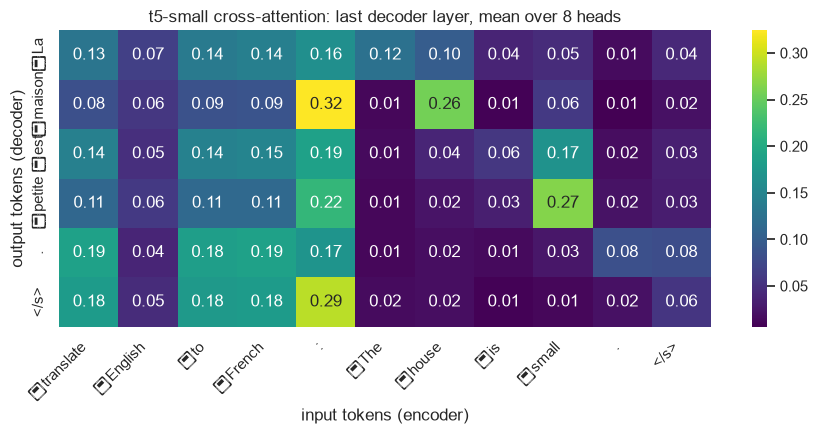

▁La        attends most to  ->  :
▁maison    attends most to  ->  :
▁est       attends most to  ->  :
▁petite    attends most to  ->  ▁small
.          attends most to  ->  ▁French
</s>       attends most to  ->  :


In [31]:
src_text = 'translate English to French: The house is small.'
tgt_text = 'La maison est petite.'

src = t5_tok(src_text, return_tensors='pt')
labels = t5_tok(tgt_text, return_tensors='pt').input_ids

with torch.no_grad():
    t5_out = t5(input_ids=src.input_ids, labels=labels, output_attentions=True)

cross = t5_out.cross_attentions
print('number of decoder layers:', len(cross), '| last layer shape:', tuple(cross[-1].shape),
      '(batch, heads, output tokens, input tokens)')

cross_avg = cross[-1][0].mean(dim=0).numpy()           # last decoder layer, mean over 8 heads
src_tokens = t5_tok.convert_ids_to_tokens(src.input_ids[0])
tgt_tokens = t5_tok.convert_ids_to_tokens(labels[0])

plt.figure(figsize=(9, 4.5))
sns.heatmap(cross_avg, cmap='viridis', annot=True, fmt='.2f', xticklabels=src_tokens, yticklabels=tgt_tokens)
plt.xlabel('input tokens (encoder)')
plt.ylabel('output tokens (decoder)')
plt.title('t5-small cross-attention: last decoder layer, mean over 8 heads')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('plots/cross_attention.png', dpi=150)
plt.show()

for i, t in enumerate(tgt_tokens):
    print(f'{t:10s} attends most to  ->  {src_tokens[cross_avg[i].argmax()]}')



## 5.5 Inference is autoregressive: manual loop

In [32]:
prompt = 'Artificial intelligence will'
input_ids = gpt_tok(prompt, return_tensors='pt').input_ids
manual_ids = input_ids.clone()

for step in range(20):
    with torch.no_grad():
        logits = gpt(manual_ids).logits                  # (1, length, vocab)
    next_id = logits[:, -1, :].argmax(dim=-1, keepdim=True)
    manual_ids = torch.cat([manual_ids, next_id], dim=1)

manual_text = gpt_tok.decode(manual_ids[0])
print('manual loop :', manual_text)

with torch.no_grad():
    gen_ids = gpt.generate(input_ids, max_new_tokens=20, do_sample=False,
                           pad_token_id=gpt_tok.eos_token_id)
gen_text = gpt_tok.decode(gen_ids[0])
print('generate()  :', gen_text)
print()
print('IDENTICAL:', torch.equal(manual_ids, gen_ids))

manual loop : Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
generate()  : Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

IDENTICAL: True



## 5.6 Decoding strategies

In [33]:
prompt = 'Artificial intelligence will'
input_ids = gpt_tok(prompt, return_tensors='pt').input_ids
common = dict(max_new_tokens=40, pad_token_id=gpt_tok.eos_token_id)

def gen(seed=None, **kw):
    if seed is not None:
        torch.manual_seed(seed)
    with torch.no_grad():
        ids = gpt.generate(input_ids, **common, **kw)
    return gpt_tok.decode(ids[0][input_ids.shape[1]:], skip_special_tokens=True)

def distinct(text):
    words = text.split()
    return round(len(set(words)) / max(len(words), 1), 2)

runs = [
    ('(a) greedy',                   gen(do_sample=False)),
    ('(b) beam search, 5 beams',     gen(num_beams=5, early_stopping=True, do_sample=False)),
    ('(c) temperature 0.7, seed 1',  gen(seed=1, do_sample=True, temperature=0.7, top_k=0)),
    ('(c) temperature 0.7, seed 2',  gen(seed=2, do_sample=True, temperature=0.7, top_k=0)),
    ('(d) temperature 1.5, seed 1',  gen(seed=1, do_sample=True, temperature=1.5, top_k=0)),
    ('(d) temperature 1.5, seed 2',  gen(seed=2, do_sample=True, temperature=1.5, top_k=0)),
    ('(e) top_k=50, top_p=0.9',      gen(seed=1, do_sample=True, top_k=50, top_p=0.9)),
]

decoding_table = pd.DataFrame({'strategy': [r[0] for r in runs],
                               'output': [r[1].replace('\n', ' ') for r in runs],
                               'distinct-word ratio': [distinct(r[1]) for r in runs]})
pd.set_option('display.max_colwidth', 220)
decoding_table

,strategy,output,distinct-word ratio
0,(a) greedy,"be able to do things like search for and find people, and to do things like find out who's in the right place at the right time. ""We're going to be able to",0.64
1,"(b) beam search, 5 beams","be the next big thing, and it's going to take a lot of work to get there. ""I think it's going to take a lot of work to get there,"" he said",0.66
2,"(c) temperature 0.7, seed 1","help us shape the future of the world. I am really excited about the future of AI. It is already possible to solve problems of intelligence, computation, and communication and it is also possible",0.76
3,"(c) temperature 0.7, seed 2",not be able to solve problems that have never been solved. The researchers note that the story of the self-driving car is like a tale of two halves: one is a self-driving,0.81
4,"(d) temperature 1.5, seed 1","upset inertia in difficult news ones. Countries humans would respect assimil c about every trial, scaven- Detection organizations from the above won % of dislressed orally Fastaturation rofter going judge sentenced ...",1.00
5,"(d) temperature 1.5, seed 2",not similarly distress down that angry increase paradigm and presume elsear characterShell pervasive strandsUpon childinitiality gradient spweet votingIn acid GUI libraries pigples are choosing SpecificesKennlaus co...,1.00
6,"(e) top_k=50, top_p=0.9","help with our search, and perhaps even help us decide which products to buy and which ones not to buy at the moment. I suspect this technology will have its future in the form of advertising, or",0.84




## 5.7 KV-cache speed-up

In [34]:
prompt_ids = gpt_tok('Artificial intelligence will', return_tensors='pt').input_ids

def time_generate(use_cache, runs=3):
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        with torch.no_grad():
            gpt.generate(prompt_ids, max_new_tokens=100, min_new_tokens=100, do_sample=False,
                         use_cache=use_cache, pad_token_id=gpt_tok.eos_token_id)
        times.append(time.perf_counter() - t0)
    return float(np.mean(times))

# warm-up so that the first call does not distort the numbers
with torch.no_grad():
    gpt.generate(prompt_ids, max_new_tokens=5, do_sample=False, pad_token_id=gpt_tok.eos_token_id)

t_no_cache = time_generate(False)
t_cache = time_generate(True)

print(f'use_cache=False: {t_no_cache:.2f} s')
print(f'use_cache=True : {t_cache:.2f} s')
print(f'speed-up       : {t_no_cache / t_cache:.1f}x')

use_cache=False: 12.74 s
use_cache=True : 5.65 s
speed-up       : 2.3x


# Task 6: Mini Application, Evaluation & Disadvantages in Practice
.

## 6.1 Evaluate the pretrained sentiment model
No training happens here. The model was fine-tuned on a different dataset (SST-2, movie-review sentences), so this is a test of how well it transfers to full IMDB reviews.

Generating unsupervised split: 100%|██████████| 50000/50000 [00:00<00:00, 229913.31 examples/s]


reviews: 200 | positive: 96 | negative: 104

accuracy : 0.87
precision: 0.8889
recall   : 0.8333
F1       : 0.8602
time     : 70.2 s for 200 reviews


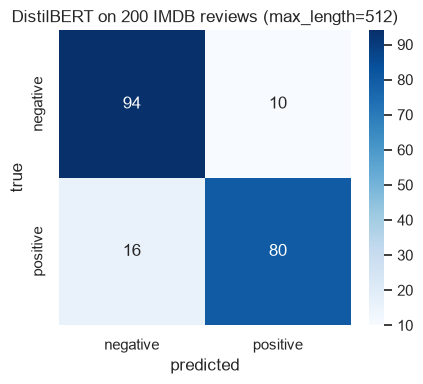

In [35]:
ds = load_dataset('stanfordnlp/imdb', split='test').shuffle(seed=42).select(range(200))
texts = list(ds['text'])
y_true = np.array(ds['label'])
print('reviews:', len(texts), '| positive:', int(y_true.sum()), '| negative:', int((y_true == 0).sum()))

def predict_labels(max_length):
    out = clf(texts, truncation=True, max_length=max_length, batch_size=16)
    return np.array([1 if o['label'] == 'POSITIVE' else 0 for o in out])

t0 = time.perf_counter()
y_pred = predict_labels(512)
t_512 = time.perf_counter() - t0

print()
print('accuracy :', round(accuracy_score(y_true, y_pred), 4))
print('precision:', round(precision_score(y_true, y_pred), 4))
print('recall   :', round(recall_score(y_true, y_pred), 4))
print('F1       :', round(f1_score(y_true, y_pred), 4))
print(f'time     : {t_512:.1f} s for 200 reviews')

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
plt.xlabel('predicted')
plt.ylabel('true')
plt.title('DistilBERT on 200 IMDB reviews (max_length=512)')
plt.tight_layout()
plt.savefig('plots/confusion_matrix.png', dpi=150)
plt.show()

## 6.2 Effect of truncation length

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


 max_length  accuracy     F1  time (s)
         64     0.750 0.7253      14.5
        128     0.775 0.7692      13.6
        256     0.840 0.8261      17.6
        512     0.870 0.8602      64.6

reviews longer than 512 tokens: 18 of 200 ( 9.0 % ) - these lose text even at max_length=512
median length: 207 tokens | longest: 1453


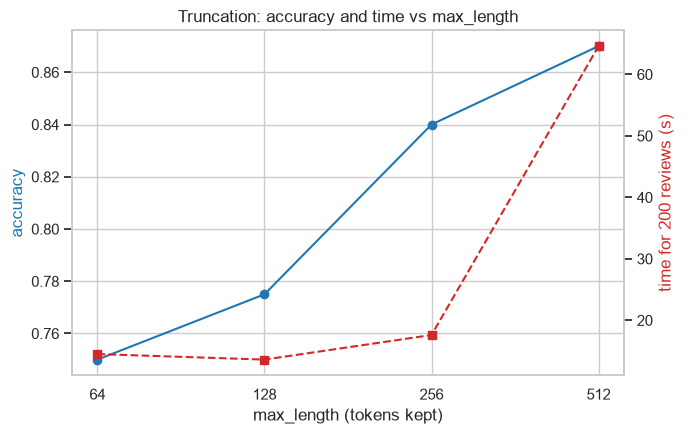

In [36]:
lengths = [64, 128, 256, 512]
rows = []
for L in lengths:
    t0 = time.perf_counter()
    pred = predict_labels(L)
    dt = time.perf_counter() - t0
    rows.append({'max_length': L, 'accuracy': round(accuracy_score(y_true, pred), 4),
                 'F1': round(f1_score(y_true, pred), 4), 'time (s)': round(dt, 1)})
trunc_table = pd.DataFrame(rows)
print(trunc_table.to_string(index=False))

token_counts = np.array([len(tok(t)['input_ids']) for t in texts])
over_512 = int((token_counts > 512).sum())
print()
print('reviews longer than 512 tokens:', over_512, 'of 200 (', over_512 / 2, '% ) - these lose text even at max_length=512')
print('median length:', int(np.median(token_counts)), 'tokens | longest:', int(token_counts.max()))

fig, ax1 = plt.subplots(figsize=(7, 4.5))
ax1.plot(trunc_table['max_length'], trunc_table['accuracy'], 'o-', color='tab:blue')
ax1.set_xlabel('max_length (tokens kept)')
ax1.set_ylabel('accuracy', color='tab:blue')
ax1.set_xscale('log', base=2)
ax1.set_xticks(lengths)
ax1.set_xticklabels(lengths)
ax2 = ax1.twinx()
ax2.plot(trunc_table['max_length'], trunc_table['time (s)'], 's--', color='tab:red')
ax2.set_ylabel('time for 200 reviews (s)', color='tab:red')
ax2.grid(False)
plt.title('Truncation: accuracy and time vs max_length')
plt.tight_layout()
plt.savefig('plots/truncation_accuracy.png', dpi=150)
plt.show()



## 6.3 Cost grows with sequence length

 tokens  forward time (ms)  x slower than 32 tokens
     32             132.38                      1.0
     64              56.56                      0.4
    128              64.47                      0.5
    256             123.20                      0.9
    512             216.44                      1.6

log-log slope of time vs length: 0.25   (1 = linear, 2 = quadratic)


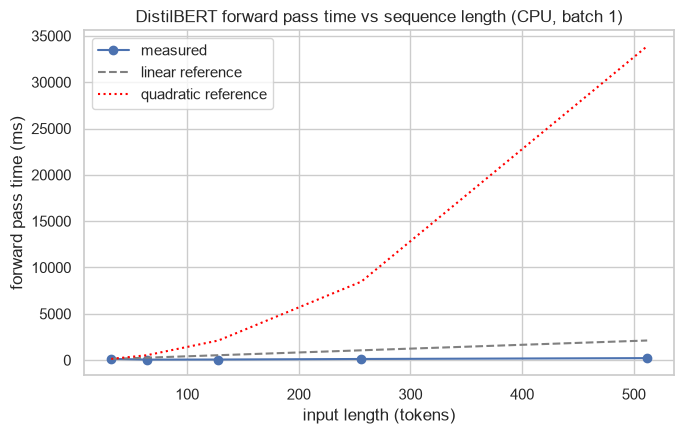

In [37]:
long_text = ' '.join(texts[:50])
long_ids = tok(long_text, add_special_tokens=False)['input_ids']

def make_input(L):
    ids = [tok.cls_token_id] + long_ids[:L - 2] + [tok.sep_token_id]
    return torch.tensor([ids])

test_lengths = [32, 64, 128, 256, 512]
mean_times = []
with torch.no_grad():
    sent_model(make_input(32))                         # warm-up
    for L in test_lengths:
        x = make_input(L)
        runs = []
        for _ in range(10):
            t0 = time.perf_counter()
            sent_model(x)
            runs.append(time.perf_counter() - t0)
        mean_times.append(np.mean(runs) * 1000)

time_table = pd.DataFrame({'tokens': test_lengths, 'forward time (ms)': np.round(mean_times, 2)})
time_table['x slower than 32 tokens'] = (time_table['forward time (ms)'] / time_table['forward time (ms)'][0]).round(1)
print(time_table.to_string(index=False))

slope = np.polyfit(np.log(test_lengths), np.log(mean_times), 1)[0]
print()
print(f'log-log slope of time vs length: {slope:.2f}   (1 = linear, 2 = quadratic)')

quad = mean_times[0] * (np.array(test_lengths) / test_lengths[0]) ** 2
lin = mean_times[0] * (np.array(test_lengths) / test_lengths[0])
plt.figure(figsize=(7, 4.5))
plt.plot(test_lengths, mean_times, 'o-', label='measured')
plt.plot(test_lengths, lin, '--', color='grey', label='linear reference')
plt.plot(test_lengths, quad, ':', color='red', label='quadratic reference')
plt.xlabel('input length (tokens)')
plt.ylabel('forward pass time (ms)')
plt.title('DistilBERT forward pass time vs sequence length (CPU, batch 1)')
plt.legend()
plt.tight_layout()
plt.savefig('plots/time_vs_length.png', dpi=150)
plt.show()



## 6.4 Hallucination check

In [38]:
fact_prompts = [
    ('The capital of Australia is', 'canberra'),
    ('The author of the novel Pride and Prejudice is', 'austen'),
    ('The inventor of the telephone was', 'bell'),
]

halluc_rows = []
for prompt, keyword in fact_prompts:
    ids = gpt_tok(prompt, return_tensors='pt').input_ids
    with torch.no_grad():
        o = gpt.generate(ids, max_new_tokens=30, do_sample=False, pad_token_id=gpt_tok.eos_token_id)
    text = gpt_tok.decode(o[0][ids.shape[1]:], skip_special_tokens=True).replace('\n', ' ')
    auto = 'correct' if keyword in text.lower() else 'wrong'
    halluc_rows.append({'prompt': prompt, 'GPT-2 continuation (30 tokens)': text, 'auto grade': auto})

halluc_table = pd.DataFrame(halluc_rows)
halluc_table

,prompt,GPT-2 continuation (30 tokens),auto grade
0,The capital of Australia is,"the world's largest producer of coal, and the country's largest coal-fired power station. The coal industry is also the world's largest",wrong
1,The author of the novel Pride and Prejudice is,a former member of the National Security Council. The author of the novel is a former member of the National Security Council. The author,wrong
2,The inventor of the telephone was,a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who,wrong


In [39]:
# the keyword check is only a first guess: read the outputs above and fix the grade by hand.
# use 'correct', 'partly correct' or 'wrong'
manual_grades = {
    # 0: 'wrong',
    # 1: 'partly correct',
}

halluc_table['final grade'] = [manual_grades.get(i, g) for i, g in enumerate(halluc_table['auto grade'])]
halluc_table[['prompt', 'final grade']]

,prompt,final grade
0,The capital of Australia is,wrong
1,The author of the novel Pride and Prejudice is,wrong
2,The inventor of the telephone was,wrong




## 6.5 Build the mini application

In [40]:
MAX_CHARS_WARN = 20000

def text_toolkit(text):
    # returns sentiment label + score, a short summary and its French translation
    if text is None or not isinstance(text, str) or len(text.strip()) == 0:
        return {'sentiment': 'n/a', 'score': None, 'summary': 'Empty input, nothing to analyse.',
                'french': '', 'note': 'empty input'}

    note = ''
    words = text.split()
    n_tokens = len(tok(text)['input_ids'])
    if n_tokens > 512:
        note = f'input has {n_tokens} tokens, truncated to 512 (the model cannot read more)'

    s = clf(text, truncation=True, max_length=512)[0]

    # very short input: summary would be longer than the text, so keep it small
    min_len = min(20, max(2, len(words) // 3))
    max_len = 60
    summary = t5_run('summarization', text, max_length=max_len, min_length=min_len)[0]
    french = t5_run('translation_en_to_fr', summary, max_length=120)[0]

    return {'sentiment': s['label'], 'score': round(s['score'], 4), 'summary': summary,
            'french': french, 'note': note}


passage_review = (
    "I bought these headphones two weeks ago and I am very happy with them. The sound is clear, the bass is "
    "strong without being too loud, and the battery easily lasts a whole working day. The only small problem "
    "is that the ear cushions get warm after a couple of hours, but for the price I think they are a great deal."
)
passage_news = paragraph
passage_own = (
    "Last weekend I spent two days preparing for my exam. The first day was hard because I could not focus, "
    "but on the second day I made a plan and finished three chapters. I still feel a little nervous, but I "
    "also feel that I understand the topics much better than before."
)

passages = {'product review': passage_review, 'news paragraph': passage_news, 'my own passage': passage_own}
rows = []
for name, p in passages.items():
    r = text_toolkit(p)
    r['passage'] = name
    rows.append(r)

toolkit_df = pd.DataFrame(rows)[['passage', 'sentiment', 'score', 'summary', 'french', 'note']]
pd.set_option('display.max_colwidth', 160)
toolkit_df

,passage,sentiment,score,summary,french,note
0,product review,POSITIVE,0.9986,"ear cushions get warm after a couple of hours, but for the price they are a great deal.","Les coussins oreilles sont chauds après quelques heures, mais pour le prix, ils sont très chers.",
1,news paragraph,NEGATIVE,0.9305,the first forty buses will arrive early next year and will serve the busiest routes through the centre. electric buses are expected to cut fuel and maintena...,Les autobus électriques devraient réduire de près d'un tiers les coûts de carburant et d'entretien. Les critiques s'inquiètent des retards dans la livraison...,
2,my own passage,POSITIVE,0.9913,last weekend I spent two days preparing for my exam. the first day was hard because I could not focus. on the second day I made a plan and finished three ch...,"le week-end dernier, j'ai passé deux jours à préparer mon examen. le premier jour a été difficile parce que je ne pouvais pas m'axer. le deuxième jour, j'ai...",


In [41]:
# graceful handling of bad input
print('empty      :', text_toolkit(''))
print('whitespace :', text_toolkit('    '))
print('not a text :', text_toolkit(None))
print()
very_long = ' '.join(texts[:6])                       # several reviews glued together
r = text_toolkit(very_long)
print('very long  :', r['note'])
print('             sentiment =', r['sentiment'], '| score =', r['score'])

empty      : {'sentiment': 'n/a', 'score': None, 'summary': 'Empty input, nothing to analyse.', 'french': '', 'note': 'empty input'}
whitespace : {'sentiment': 'n/a', 'score': None, 'summary': 'Empty input, nothing to analyse.', 'french': '', 'note': 'empty input'}
not a text : {'sentiment': 'n/a', 'score': None, 'summary': 'Empty input, nothing to analyse.', 'french': '', 'note': 'empty input'}

very long  : input has 1261 tokens, truncated to 512 (the model cannot read more)
             sentiment = POSITIVE | score = 0.9987


## 6.6 What I learned about Transformers



In [42]:
acc64 = trunc_table.loc[trunc_table['max_length'] == 64, 'accuracy'].iloc[0]
acc512 = trunc_table.loc[trunc_table['max_length'] == 512, 'accuracy'].iloc[0]
t64 = trunc_table.loc[trunc_table['max_length'] == 64, 'time (s)'].iloc[0]
t512_ = trunc_table.loc[trunc_table['max_length'] == 512, 'time (s)'].iloc[0]

print(f'Truncation : accuracy {acc64:.3f} at 64 tokens vs {acc512:.3f} at 512 tokens '
      f'({(acc512 - acc64) * 100:.1f} points lost); time {t64}s vs {t512_}s; {over_512}/200 reviews exceed 512 tokens.')
print(f'Cost       : {mean_times[0]:.1f} ms at 32 tokens -> {mean_times[-1]:.1f} ms at 512 tokens '
      f'({mean_times[-1] / mean_times[0]:.1f}x slower for 16x more tokens), log-log slope {slope:.2f}.')
print(f'KV cache   : {t_no_cache / t_cache:.1f}x faster generation with use_cache=True.')
print(f'Sentiment  : accuracy {accuracy_score(y_true, y_pred):.3f}, F1 {f1_score(y_true, y_pred):.3f} on 200 IMDB reviews.')

Truncation : accuracy 0.750 at 64 tokens vs 0.870 at 512 tokens (12.0 points lost); time 14.5s vs 64.6s; 18/200 reviews exceed 512 tokens.
Cost       : 132.4 ms at 32 tokens -> 216.4 ms at 512 tokens (1.6x slower for 16x more tokens), log-log slope 0.25.
KV cache   : 2.3x faster generation with use_cache=True.
Sentiment  : accuracy 0.870, F1 0.860 on 200 IMDB reviews.


## 6.7 Notebook quality


In [43]:
import importlib.metadata as md

used = ['transformers', 'torch', 'datasets', 'matplotlib', 'seaborn', 'numpy', 'pandas', 'scikit-learn', 'sentencepiece']
lines = []
for pkg in used:
    try:
        lines.append(f'{pkg}=={md.version(pkg)}')
    except md.PackageNotFoundError:
        pass

with open('requirements.txt', 'w') as f:
    f.write('\n'.join(lines) + '\n')

print('requirements.txt written:')
print('\n'.join(lines))
print()
print('saved plots:', sorted(os.listdir('plots')))

requirements.txt written:
transformers==5.20.2
torch==2.14.0
datasets==5.1.0
matplotlib==3.11.1
seaborn==0.13.2
numpy==2.4.6
pandas==3.0.5
scikit-learn==1.9.0

saved plots: ['.gitkeep', 'attention_bidirectional.png', 'attention_heads.png', 'attention_scratch.png', 'causal_mask.png', 'causal_vs_bidirectional.png', 'confusion_matrix.png', 'cross_attention.png', 'head_entropy.png', 'learned_positions.png', 'parameter_distribution.png', 'positional_encoding.png', 'time_vs_length.png', 'truncation_accuracy.png']
